
# 05 — Occlusion Sensitivity: Explanation Generation and Robustness Pilot

### Role in the Overall Project

This notebook implements Occlusion Sensitivity, one of three post-hoc explanation methods evaluated in the project.

The notebook uses a pilot sample of 12 correctly classified held-out chest X-rays to examine explanation generation, robustness under Gaussian blur and noise, and localization alignment.

The final evaluation is conducted separately using 300 held-out images, including 150 positive and 150 negative cases.

The primary stability–localization disagreement audit uses 150 annotated positive images across three explanation methods and six corruption conditions, resulting in 2,700 repeated evaluations.

The central question is whether high explanation stability necessarily implies preservation of localization alignment.

This notebook establishes the Occlusion Sensitivity component of that investigation.


## References

1. Zeiler, M. D., & Fergus, R. (2014). Visualizing and understanding convolutional networks. In *Computer Vision – ECCV 2014* (pp. 818–833). Springer. https://doi.org/10.1007/978-3-319-10590-1_53

2. Talaat, M., Si, X., & Xi, J. (2023). Multi-level training and testing of CNN models in diagnosing multi-center COVID-19 and pneumonia X-ray images. *Applied Sciences, 13*(18), 10270. https://doi.org/10.3390/app131810270


In [ ]:
!pip install pydicom

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 27.8 MB/s eta 0:00:00



## 1. Environment Setup and Model Loading

This section prepares the Google Colab environment, defines the project directories, verifies required files, and loads the previously trained ResNet50 classifier.

The model checkpoint (`resnet50_best.pth`) contains weights obtained during the training stage of the project.

We use `model.eval()` to place the network in evaluation mode. The model is not retrained on the pilot images.

The same saved classifier is used for Score-CAM, Integrated Gradients, and Occlusion Sensitivity, allowing us to compare different explanation methods without introducing differences caused by retraining.


In [ ]:

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import sys
import json
import time
import shutil
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import torch
import torch.nn as nn
import pydicom

from scipy.stats import spearmanr
from tqdm.auto import tqdm

# Project directories
PROJECT_DIR = Path(
    "/content/drive/MyDrive/XAI_project_Expo_1_folder"
)

DATA_DIR = PROJECT_DIR / "Data"
MODEL_DIR = PROJECT_DIR / "Models"
RESULTS_DIR = PROJECT_DIR / "Results"

OCCLUSION_DIR = RESULTS_DIR / "OcclusionSensitivity"
MAPS_DIR = OCCLUSION_DIR / "Maps"

OCCLUSION_DIR.mkdir(parents=True, exist_ok=True)
MAPS_DIR.mkdir(parents=True, exist_ok=True)

# Add project utility module to Python's import path
UTILS_DIR = PROJECT_DIR / "__pycache__"
sys.path.insert(0, str(UTILS_DIR))

# GPU setup
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Project directory:", PROJECT_DIR)
print("Occlusion results directory:", OCCLUSION_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda
Project directory: /content/drive/MyDrive/XAI_project_Expo_1_folder
Occlusion results directory: /content/drive/MyDrive/XAI_project_Expo_1_folder/Results/OcclusionSensitivity


In [ ]:

# Required project artifacts
required_files = {
    "Best ResNet50 model": MODEL_DIR / "resnet50_best.pth",
    "Pilot image selection": DATA_DIR / "pilot_selected_images.csv",
    "Dataset split": DATA_DIR / "model_dataset_split.csv",
    "RSNA annotations": (
        DATA_DIR
        / "pneumonia-challenge-annotations-adjudicated-kaggle_2018.json"
    ),
    "RSNA DICOM archive": (
        DATA_DIR
        / "pneumonia-challenge-dataset-adjudicated-kaggle_2018.zip"
    ),
    "XAI utility functions": PROJECT_DIR / "xai_utils.py",
}

all_found = True

for name, path in required_files.items():
    exists = path.is_file()
    status = "FOUND" if exists else "MISSING"

    print(f"{status:7} | {name}")

    if not exists:
        print("         Expected path:", path)
        all_found = False

print("\nReady to proceed:", all_found)


FOUND   | Best ResNet50 model
FOUND   | Pilot image selection
FOUND   | Dataset split
FOUND   | RSNA annotations
FOUND   | RSNA DICOM archive
FOUND   | XAI utility functions

Ready to proceed: True


In [ ]:
# Import our existing XAI utility functions
sys.path.insert(0, str(PROJECT_DIR))

from xai_utils import load_trained_model

# Load the saved ResNet50 model
model = load_trained_model(
    MODEL_DIR / "resnet50_best.pth",
    device
)

model.eval()

# Load the 12 selected pilot images
pilot_images = pd.read_csv(
    DATA_DIR / "pilot_selected_images.csv"
)

print("Model loaded successfully!")
print("Pilot images:", len(pilot_images))
print("\nPilot group distribution:")
print(pilot_images["pilot_group"].value_counts())

print("\nGPU device:", device)

Model loaded successfully!
Pilot images: 12

Pilot group distribution:
pilot_group
Positive    6
Negative    6
Name: count, dtype: int64

GPU device: cuda


In [ ]:
import sys
sys.path.insert(0, str(PROJECT_DIR))

from xai_utils import load_trained_model

print("XAI utility functions imported successfully!")

XAI utility functions imported successfully!



## 2. Pilot Image Selection and Preprocessing

We use 12 previously selected, correctly classified test images:

- 6 images classified correctly as Lung Opacity (positive cases).
- 6 images classified correctly as No Lung Opacity (negative cases).

The selected images are extracted from the original RSNA DICOM archive.

Each image is loaded and resized to **320 × 384 pixels**. The grayscale image is converted into a three-channel tensor and normalized using ImageNet normalization parameters before being passed to ResNet50.

Using the same pilot images across all three explainability methods ensures that comparisons are performed on the same cases.

This is a small exploratory sample rather than a representative evaluation of the entire test dataset.


In [ ]:
# Extract only the 12 pilot images from the RSNA ZIP archive

ZIP_PATH = DATA_DIR / "pneumonia-challenge-dataset-adjudicated-kaggle_2018.zip"

LOCAL_PILOT_DIR = Path("/content/rsna_pilot_images")
LOCAL_PILOT_DIR.mkdir(parents=True, exist_ok=True)

pilot_filenames = {
    f"{uid}.dcm"
    for uid in pilot_images["sop_uid"].astype(str)
}

extracted = set()

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    for member in zf.infolist():
        filename = Path(member.filename).name

        if filename in pilot_filenames:
            destination = LOCAL_PILOT_DIR / filename

            if not destination.exists():
                with zf.open(member) as source:
                    with open(destination, "wb") as target:
                        shutil.copyfileobj(source, target)

            extracted.add(filename)

print("Pilot images requested:", len(pilot_filenames))
print("Pilot images found in archive:", len(extracted))
print("Local DICOM files:", len(list(LOCAL_PILOT_DIR.glob("*.dcm"))))

Pilot images requested: 12
Pilot images found in archive: 12
Local DICOM files: 12


Original image shape: (1024, 1024)
Resized image shape: (320, 384)
Pixel range: 0.002144608 0.9948529


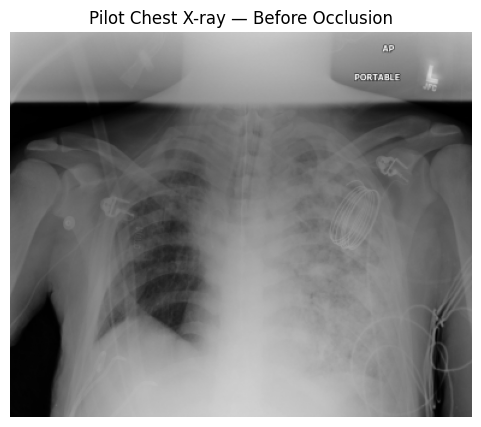

In [ ]:
from xai_utils import load_dicom, resize_image

# Select the first pilot image
sample_uid = str(pilot_images.iloc[0]["sop_uid"])
sample_path = LOCAL_PILOT_DIR / f"{sample_uid}.dcm"

# Read and resize the image
sample_image = load_dicom(sample_path)
sample_resized = resize_image(sample_image)

print("Original image shape:", sample_image.shape)
print("Resized image shape:", sample_resized.shape)
print("Pixel range:", sample_resized.min(), sample_resized.max())

plt.figure(figsize=(6, 5))
plt.imshow(sample_resized, cmap="gray")
plt.title("Pilot Chest X-ray — Before Occlusion")
plt.axis("off")
plt.show()

In [ ]:
from xai_utils import prepare_corrupted_image

# Convert resized grayscale image into normalized model input
sample_tensor = prepare_corrupted_image(sample_resized)
sample_tensor = sample_tensor.unsqueeze(0).to(device)

# Get model prediction
model.eval()

with torch.no_grad():
    original_logit = model(sample_tensor).squeeze()
    original_probability = torch.sigmoid(original_logit).item()

sample_group = pilot_images.iloc[0]["pilot_group"]
sample_target = int(pilot_images.iloc[0]["target"])

print("Pilot group:", sample_group)
print("Ground-truth target:", sample_target)
print(f"Predicted lung-opacity probability: {original_probability:.4f}")
print("Predicted class:", int(original_probability >= 0.5))
print("Correct classification:",
      int(original_probability >= 0.5) == sample_target)

Pilot group: Positive
Ground-truth target: 1
Predicted lung-opacity probability: 0.8987
Predicted class: 1
Correct classification: True



## 3. Understanding Occlusion Sensitivity

Occlusion Sensitivity is a perturbation-based explanation technique.

Instead of calculating gradients, the method evaluates how the model's output changes when a small region of the input image is hidden.

### Procedure

1. Obtain the model's original output for an image.
2. Cover a small region of the image with a black square.
3. Pass the modified image through the same trained model.
4. Measure the change in the target-class score.
5. Repeat this procedure across the image to construct an attribution map.

Regions where occlusion produces a larger change in the target-class score are considered more influential for the prediction.

### Parameters

- **Occlusion window:** 32 × 32 pixels
- **Stride:** 16 pixels
- **Occlusion replacement value:** 0 (black, in the resized grayscale image)
- **Batch size:** 32 modified images

Overlapping windows contribute to the final attribution map, and their effects are averaged.

### Important Consideration

Occlusion Sensitivity does not directly identify disease. It measures how sensitive the trained classifier is to removing information from different image regions.

Additionally, black squares may introduce artificial visual patterns that do not naturally occur in chest X-rays. This is an important limitation of the method.


### 3.1 Related Work

Zeiler and Fergus (2014) explored occlusion-based visualization as a way to investigate which image regions influence convolutional neural network predictions.

Talaat et al. (2023) applied Occlusion Sensitivity to chest X-ray classification, including pneumonia and COVID-19, and examined the resulting visualizations across different CNN configurations.

The present project extends this application by evaluating how Occlusion Sensitivity explanations respond to Gaussian blur and noise, particularly whether explanation stability corresponds to preserved alignment with radiologist-annotated opacity regions.


Original probability: 0.8987
Occluded probability: 0.8470
Probability change: +0.0518


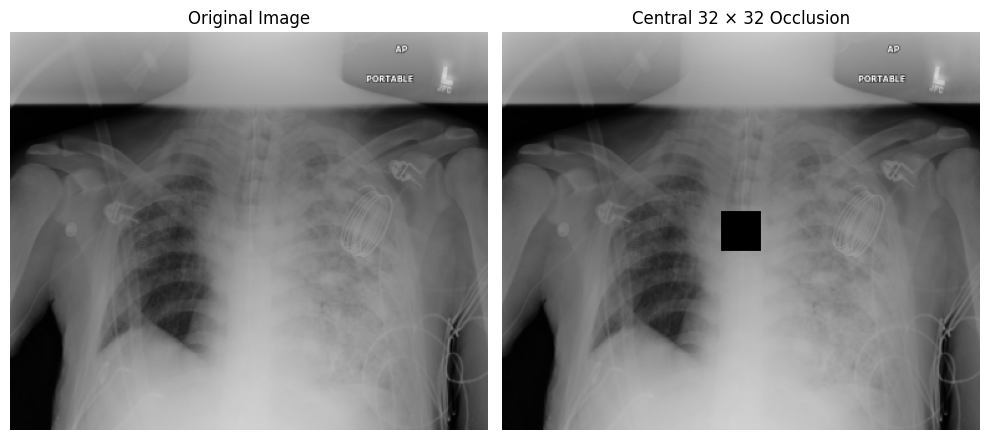

In [ ]:
# Make a copy of the original resized image
occluded_image = sample_resized.copy()

# Define a 32 x 32 pixel occlusion window
window_size = 32

height, width = occluded_image.shape

y_start = height // 2 - window_size // 2
x_start = width // 2 - window_size // 2

# Replace the covered region with zero intensity
occluded_image[
    y_start:y_start + window_size,
    x_start:x_start + window_size
] = 0.0

# Prepare model input
occluded_tensor = prepare_corrupted_image(
    occluded_image
).unsqueeze(0).to(device)

# Predict after occlusion
with torch.no_grad():
    occluded_logit = model(occluded_tensor).squeeze()
    occluded_probability = torch.sigmoid(occluded_logit).item()

print(f"Original probability: {original_probability:.4f}")
print(f"Occluded probability: {occluded_probability:.4f}")
print(f"Probability change: {original_probability - occluded_probability:+.4f}")

# Visual comparison
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(sample_resized, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Original Image")

axes[1].imshow(occluded_image, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Central 32 × 32 Occlusion")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


## 4. Implementing Occlusion Sensitivity

The function `generate_occlusion_map()` systematically applies occlusion windows across an input image and measures changes in the model's target-class logit.

For positive pilot images, the target score is the Lung Opacity logit. For negative pilot images, the target score is the negative of that logit, representing evidence toward the No Lung Opacity class in this binary classifier.

The attribution at each location is calculated using the difference between the original target score and the score obtained after occlusion.

The resulting **signed attribution map** distinguishes regions whose removal decreases or increases the target-class score.

For the stability and localization analyses, we use the **absolute magnitude** of these attributions. Consequently, both positive and negative occlusion effects contribute to the evaluation.

The model weights remain unchanged during this process.


In [ ]:
def generate_occlusion_map(
    image,
    model,
    device,
    target_class=1,
    window_size=32,
    stride=16,
    batch_size=32
):
    """
    Generate an Occlusion Sensitivity map for one grayscale image.

    image: resized grayscale image, shape (320, 384), range [0, 1]
    target_class: 1 for Lung Opacity, 0 for No Lung Opacity
    """

    model.eval()

    height, width = image.shape

    # Prepare original image
    original_tensor = prepare_corrupted_image(
        image
    ).unsqueeze(0).to(device)

    with torch.no_grad():
        original_logit = model(original_tensor).flatten()[0].item()

    # Use the same class-specific target convention as previous XAI methods
    target_sign = 1 if target_class == 1 else -1
    original_score = target_sign * original_logit

    attribution_sum = np.zeros((height, width), dtype=np.float32)
    attribution_count = np.zeros((height, width), dtype=np.float32)

    # Include the image boundaries
    y_positions = list(range(0, height - window_size + 1, stride))
    x_positions = list(range(0, width - window_size + 1, stride))

    if y_positions[-1] != height - window_size:
        y_positions.append(height - window_size)

    if x_positions[-1] != width - window_size:
        x_positions.append(width - window_size)

    occluded_batch = []
    window_coordinates = []

    def process_batch():
        if not occluded_batch:
            return

        batch_tensor = torch.stack(occluded_batch).to(device)

        with torch.no_grad():
            logits = model(batch_tensor).flatten()
            scores = target_sign * logits

        score_drops = (
            original_score - scores.cpu().numpy()
        )

        for score_drop, (y, x) in zip(
            score_drops, window_coordinates
        ):
            attribution_sum[
                y:y + window_size,
                x:x + window_size
            ] += score_drop

            attribution_count[
                y:y + window_size,
                x:x + window_size
            ] += 1

        occluded_batch.clear()
        window_coordinates.clear()

    # Move the occlusion window across the image
    for y in y_positions:
        for x in x_positions:

            occluded = image.copy()

            occluded[
                y:y + window_size,
                x:x + window_size
            ] = 0.0

            tensor = prepare_corrupted_image(occluded)

            occluded_batch.append(tensor)
            window_coordinates.append((y, x))

            if len(occluded_batch) >= batch_size:
                process_batch()

    # Process remaining occlusions
    process_batch()

    # Average overlapping occlusion contributions
    occlusion_map = attribution_sum / np.maximum(
        attribution_count, 1
    )

    return occlusion_map, original_logit

Generation time: 3.89 seconds
Occlusion map shape: (320, 384)
Signed attribution range: -0.05648631 1.1790488


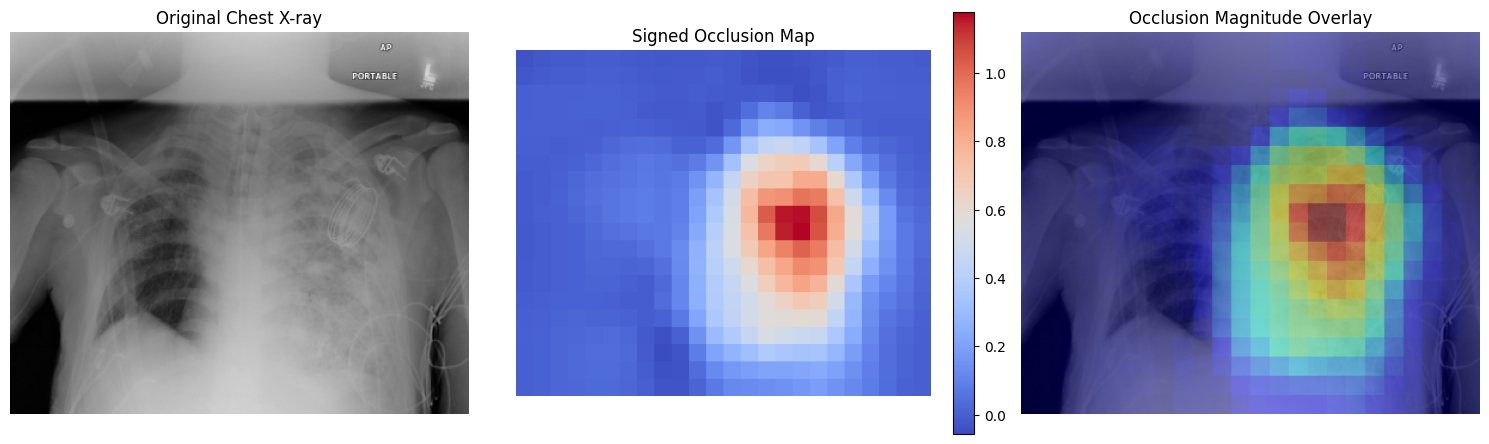

In [ ]:
start_time = time.time()

sample_occlusion_map, sample_logit = generate_occlusion_map(
    image=sample_resized,
    model=model,
    device=device,
    target_class=sample_target,
    window_size=32,
    stride=16,
    batch_size=32
)

elapsed = time.time() - start_time

# Magnitude of the attribution
sample_occlusion_magnitude = np.abs(sample_occlusion_map)

print(f"Generation time: {elapsed:.2f} seconds")
print("Occlusion map shape:", sample_occlusion_map.shape)
print("Signed attribution range:",
      sample_occlusion_map.min(),
      sample_occlusion_map.max())

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(sample_resized, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Original Chest X-ray")

im1 = axes[1].imshow(
    sample_occlusion_map,
    cmap="coolwarm"
)
axes[1].set_title("Signed Occlusion Map")
plt.colorbar(im1, ax=axes[1], fraction=0.046)

axes[2].imshow(sample_resized, cmap="gray", vmin=0, vmax=1)
axes[2].imshow(
    sample_occlusion_magnitude,
    cmap="jet",
    alpha=0.45
)
axes[2].set_title("Occlusion Magnitude Overlay")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


## 5. Gaussian Blur and Gaussian Noise Experiments

We evaluate Occlusion Sensitivity on the original images and six corrupted versions of each image.

### Gaussian Blur

Gaussian blur reduces fine image details by smoothing neighboring pixel values.

| Severity | Sigma |
|---|---:|
| Mild | 0.5 |
| Moderate | 1.5 |
| Severe | 3.0 |

### Gaussian Noise

Gaussian noise introduces random pixel-level variations.

| Severity | Standard Deviation |
|---|---:|
| Mild | 0.02 |
| Moderate | 0.05 |
| Severe | 0.10 |

Noise is generated using a fixed random seed (`42`) for reproducibility.

Each of the 12 pilot images is evaluated under seven conditions: one original and six corrupted conditions.

**Total explanation maps: 12 × 7 = 84.**

The resulting maps are saved as compressed NumPy files (`.npz`) in Google Drive so that subsequent analyses can be performed without regenerating the explanations.

These corruption levels are experimental settings and are not intended to represent calibrated levels of clinical image degradation.


In [ ]:
from xai_utils import (
    load_dicom,
    resize_image,
    apply_gaussian_blur,
    apply_gaussian_noise,
    BLUR_LEVELS,
    NOISE_LEVELS,
)

# Seven unique conditions per image
conditions = [
    ("Original", "Original", 0.0),
    ("Blur", "Mild Blur", 0.5),
    ("Blur", "Moderate Blur", 1.5),
    ("Blur", "Severe Blur", 3.0),
    ("Noise", "Mild Noise", 0.02),
    ("Noise", "Moderate Noise", 0.05),
    ("Noise", "Severe Noise", 0.10),
]

print("Number of pilot images:", len(pilot_images))
print("Conditions per image:", len(conditions))
print("Expected maps:", len(pilot_images) * len(conditions))

print("\nConfigured corruption levels:")
print("Blur:", BLUR_LEVELS)
print("Noise:", NOISE_LEVELS)

Number of pilot images: 12
Conditions per image: 7
Expected maps: 84

Configured corruption levels:
Blur: {'Original': 0.0, 'Mild Blur': 0.5, 'Moderate Blur': 1.5, 'Severe Blur': 3.0}
Noise: {'Original': 0.0, 'Mild Noise': 0.02, 'Moderate Noise': 0.05, 'Severe Noise': 0.1}


In [ ]:
import time

experiment_start = time.time()

for _, row in tqdm(
    pilot_images.iterrows(),
    total=len(pilot_images),
    desc="Pilot images"
):
    sop_uid = str(row["sop_uid"])
    pilot_group = str(row["pilot_group"])
    target_class = int(row["target"])

    dicom_path = LOCAL_PILOT_DIR / f"{sop_uid}.dcm"

    original_image = resize_image(
        load_dicom(dicom_path)
    )

    for experiment, condition, sigma in conditions:

        safe_condition = condition.lower().replace(" ", "_")

        save_path = MAPS_DIR / f"{sop_uid}_{safe_condition}.npz"

        # Skip maps already saved
        if save_path.exists():
            continue

        if experiment == "Original":
            processed_image = original_image.copy()

        elif experiment == "Blur":
            processed_image = apply_gaussian_blur(
                original_image,
                sigma
            )

        elif experiment == "Noise":
            processed_image = apply_gaussian_noise(
                original_image,
                sigma,
                seed=42
            )

        occlusion_map, original_logit = generate_occlusion_map(
            image=processed_image,
            model=model,
            device=device,
            target_class=target_class,
            window_size=32,
            stride=16,
            batch_size=32
        )

        np.savez_compressed(
            save_path,
            signed_map=occlusion_map.astype(np.float32),
            magnitude_map=np.abs(occlusion_map).astype(np.float32),
            original_logit=np.float32(original_logit),
            target_class=np.int32(target_class),
            sigma=np.float32(sigma),
            condition=condition,
            experiment=experiment,
            sop_uid=sop_uid,
            pilot_group=pilot_group,
        )

print("\nExperiment completed!")
print(f"Elapsed time: {(time.time() - experiment_start) / 60:.2f} minutes")

saved_maps = list(MAPS_DIR.glob("*.npz"))

print("Saved maps:", len(saved_maps))
print("Expected maps:", len(pilot_images) * len(conditions))

Pilot images:   0%|          | 0/12 [00:00<?, ?it/s]


Experiment completed!
Elapsed time: 5.78 minutes
Saved maps: 84
Expected maps: 84



## 6. Evaluating Explanation Stability

Explanation stability measures how similar an explanation remains after an image is corrupted.

We compare the Occlusion Sensitivity map of each corrupted image against the corresponding original-image map using **Spearman rank correlation**.

Spearman correlation measures the similarity between the rankings of attribution magnitudes across pixels.

### Interpretation

- A correlation close to **1** indicates highly similar attribution rankings.
- A correlation close to **0** indicates little rank association.
- A negative correlation indicates opposing rankings.

The original image is assigned a similarity score of 1 because it is compared with itself.

We calculate image-level correlations and then summarize them separately for positive and negative pilot images.

A high Spearman correlation indicates that the spatial ranking of attribution magnitudes is relatively stable. However, it does not establish that the explanation is faithful or medically correct.


In [ ]:
stability_rows = []

for _, row in pilot_images.iterrows():

    sop_uid = str(row["sop_uid"])
    pilot_group = str(row["pilot_group"])

    original_path = MAPS_DIR / f"{sop_uid}_original.npz"

    with np.load(original_path) as data:
        original_map = data["magnitude_map"].flatten()

    for experiment, condition, sigma in conditions:

        safe_condition = condition.lower().replace(" ", "_")
        map_path = MAPS_DIR / f"{sop_uid}_{safe_condition}.npz"

        with np.load(map_path) as data:
            corrupted_map = data["magnitude_map"].flatten()
            original_logit = float(data["original_logit"])

        if condition == "Original":
            similarity = 1.0
        else:
            similarity = spearmanr(
                original_map,
                corrupted_map
            ).statistic

        opacity_probability = float(
            torch.sigmoid(torch.tensor(original_logit))
        )

        stability_rows.append({
            "sop_uid": sop_uid,
            "pilot_group": pilot_group,
            "corruption": experiment,
            "condition": condition,
            "sigma": sigma,
            "opacity_probability": opacity_probability,
            "explanation_similarity": similarity,
        })

occlusion_stability_df = pd.DataFrame(stability_rows)

# Save individual-image results
occlusion_stability_df.to_csv(
    OCCLUSION_DIR / "occlusion_stability_results.csv",
    index=False
)

print("Stability records:", len(occlusion_stability_df))
print("Missing similarities:",
      occlusion_stability_df["explanation_similarity"].isna().sum())

display(occlusion_stability_df.head())

Stability records: 84
Missing similarities: 0


,sop_uid,pilot_group,corruption,condition,sigma,opacity_probability,explanation_similarity
0,1.2.276.0.7230010.3.1.4.8323329.2175.151787429...,Positive,Original,Original,0.00,0.898721,1.000000
1,1.2.276.0.7230010.3.1.4.8323329.2175.151787429...,Positive,Blur,Mild Blur,0.50,0.893324,0.983888
2,1.2.276.0.7230010.3.1.4.8323329.2175.151787429...,Positive,Blur,Moderate Blur,1.50,0.712182,0.792174
3,1.2.276.0.7230010.3.1.4.8323329.2175.151787429...,Positive,Blur,Severe Blur,3.00,0.579108,0.775815
4,1.2.276.0.7230010.3.1.4.8323329.2175.151787429...,Positive,Noise,Mild Noise,0.02,0.631496,0.863232


In [ ]:
# Original appears once in the saved maps but belongs
# to both the blur and noise comparison experiments.

summary_df = occlusion_stability_df.copy()

original_rows = summary_df[
    summary_df["condition"] == "Original"
].copy()

blur_original = original_rows.copy()
blur_original["corruption"] = "Blur"

noise_original = original_rows.copy()
noise_original["corruption"] = "Noise"

summary_df = pd.concat(
    [
        summary_df[summary_df["condition"] != "Original"],
        blur_original,
        noise_original,
    ],
    ignore_index=True
)

occlusion_stability_summary = (
    summary_df
    .groupby(
        ["corruption", "pilot_group", "condition"],
        as_index=False
    )
    .agg(
        mean_opacity_probability=("opacity_probability", "mean"),
        mean_spearman_similarity=("explanation_similarity", "mean"),
        std_spearman_similarity=("explanation_similarity", "std"),
        n_images=("sop_uid", "nunique"),
    )
)

occlusion_stability_summary.to_csv(
    OCCLUSION_DIR / "occlusion_stability_summary.csv",
    index=False
)

print("Summary rows:", len(occlusion_stability_summary))

display(
    occlusion_stability_summary[
        [
            "corruption",
            "pilot_group",
            "condition",
            "mean_spearman_similarity",
            "n_images",
        ]
    ].sort_values(
        ["corruption", "pilot_group", "condition"]
    )
)

Summary rows: 16


,corruption,pilot_group,condition,mean_spearman_similarity,n_images
0,Blur,Negative,Mild Blur,0.981311,6
1,Blur,Negative,Moderate Blur,0.702770,6
2,Blur,Negative,Original,1.000000,6
3,Blur,Negative,Severe Blur,0.497834,6
4,Blur,Positive,Mild Blur,0.989192,6
5,Blur,Positive,Moderate Blur,0.906392,6
6,Blur,Positive,Original,1.000000,6
7,Blur,Positive,Severe Blur,0.853553,6
8,Noise,Negative,Mild Noise,0.778832,6
9,Noise,Negative,Moderate Noise,0.570561,6



### 6.1 Explanation Stability Results

Occlusion Sensitivity explanations generally became less stable as corruption severity increased.

**Gaussian Blur**

- Positive cases: mean Spearman correlation decreased from 0.989 under mild blur to 0.854 under severe blur.
- Negative cases: mean correlation decreased from 0.981 under mild blur to 0.498 under severe blur.

**Gaussian Noise**

- Positive cases: mean correlation decreased from 0.868 under mild noise to 0.660 under severe noise.
- Negative cases: mean correlation decreased from 0.779 under mild noise to 0.309 under severe noise.

These findings suggest that Gaussian noise produced substantial changes in attribution rankings, particularly for negative pilot images.

In this sample, positive-image explanations were generally more stable than negative-image explanations at moderate and severe corruption levels.

Because each group contains only six images, these findings should be interpreted as exploratory rather than population-level conclusions.



## 7. Evaluating Localization Against Radiologist Annotations

Explanation stability alone does not indicate whether an explanation highlights medically relevant regions.

To investigate localization, we compare Occlusion Sensitivity maps against radiologist-annotated lung-opacity bounding boxes from the RSNA dataset.

This evaluation uses only the six positive pilot images, because these images have opacity-region annotations.

The localization alignment score is calculated as:

$$
\text{Alignment} =
\frac{\sum_{(x,y)\in B}|A(x,y)|}
{\sum_{(x,y)}|A(x,y)|}
$$

where:

- \(A(x,y)\) is the signed Occlusion Sensitivity attribution at pixel \((x,y)\).
- \(B\) represents the union of the radiologist-annotated opacity regions.
- The absolute value includes attribution magnitude regardless of direction.

An alignment score of 0.45 indicates that 45% of the total attribution magnitude falls inside the annotated regions.

**Important:** This metric measures spatial concentration within the annotations. It is not an object-detection accuracy score, and it does not establish that the explanation is clinically valid. Alignment can also depend on the size of the annotated regions.

In [ ]:
from xai_utils import build_opacity_lookup, calculate_alignment

ANNOTATION_PATH = (
    DATA_DIR /
    "pneumonia-challenge-annotations-adjudicated-kaggle_2018.json"
)

with open(ANNOTATION_PATH, "r") as f:
    annotations = json.load(f)

annotation_records = annotations["datasets"][0]["annotations"]

opacity_lookup = build_opacity_lookup(annotation_records)

positive_pilot = pilot_images[
    pilot_images["pilot_group"] == "Positive"
].copy()

print("Positive pilot images:", len(positive_pilot))

for _, row in positive_pilot.iterrows():
    sop_uid = str(row["sop_uid"])
    boxes = opacity_lookup.get(sop_uid, [])

    print(
        f"{sop_uid[:30]}... | "
        f"Bounding boxes: {len(boxes)}"
    )

Positive pilot images: 6
1.2.276.0.7230010.3.1.4.832332... | Bounding boxes: 1
1.2.276.0.7230010.3.1.4.832332... | Bounding boxes: 2
1.2.276.0.7230010.3.1.4.832332... | Bounding boxes: 2
1.2.276.0.7230010.3.1.4.832332... | Bounding boxes: 1
1.2.276.0.7230010.3.1.4.832332... | Bounding boxes: 2
1.2.276.0.7230010.3.1.4.832332... | Bounding boxes: 2


In [ ]:
localization_rows = []

for _, row in positive_pilot.iterrows():

    sop_uid = str(row["sop_uid"])
    boxes = opacity_lookup.get(sop_uid, [])

    if not boxes:
        continue

    for experiment, condition, sigma in conditions:

        safe_condition = condition.lower().replace(" ", "_")
        map_path = MAPS_DIR / f"{sop_uid}_{safe_condition}.npz"

        with np.load(map_path) as data:
            magnitude_map = data["magnitude_map"]

        alignment = calculate_alignment(
            magnitude_map,
            boxes
        )

        localization_rows.append({
            "sop_uid": sop_uid,
            "pilot_group": "Positive",
            "corruption": experiment,
            "condition": condition,
            "sigma": sigma,
            "alignment": alignment,
            "n_boxes": len(boxes),
        })

occlusion_localization_df = pd.DataFrame(localization_rows)

occlusion_localization_df.to_csv(
    OCCLUSION_DIR / "occlusion_localization_alignment.csv",
    index=False
)

# Duplicate original condition for both experiments
original_localization = occlusion_localization_df[
    occlusion_localization_df["condition"] == "Original"
].copy()

blur_original = original_localization.copy()
blur_original["corruption"] = "Blur"

noise_original = original_localization.copy()
noise_original["corruption"] = "Noise"

localization_summary_input = pd.concat(
    [
        occlusion_localization_df[
            occlusion_localization_df["condition"] != "Original"
        ],
        blur_original,
        noise_original,
    ],
    ignore_index=True
)

occlusion_localization_summary = (
    localization_summary_input
    .groupby(
        ["corruption", "condition"],
        as_index=False
    )
    .agg(
        mean_alignment=("alignment", "mean"),
        std_alignment=("alignment", "std"),
        n_images=("sop_uid", "nunique"),
    )
)

occlusion_localization_summary.to_csv(
    OCCLUSION_DIR / "occlusion_localization_summary.csv",
    index=False
)

print("Localization records:", len(occlusion_localization_df))
print("Summary rows:", len(occlusion_localization_summary))

display(occlusion_localization_summary)

Localization records: 42
Summary rows: 8


,corruption,condition,mean_alignment,std_alignment,n_images
0,Blur,Mild Blur,0.455898,0.219992,6
1,Blur,Moderate Blur,0.447006,0.229540,6
2,Blur,Original,0.458035,0.216505,6
3,Blur,Severe Blur,0.397644,0.216205,6
4,Noise,Mild Noise,0.381447,0.213294,6
5,Noise,Moderate Noise,0.286326,0.169919,6
6,Noise,Original,0.458035,0.216505,6
7,Noise,Severe Noise,0.243313,0.143155,6



### 7.1 Localization Results

For the original positive chest X-rays, the mean localization alignment was **0.458**, indicating that approximately 45.8% of the total absolute attribution magnitude fell inside the radiologist-annotated opacity regions.

### Gaussian Blur

| Condition | Mean Alignment |
|---|---:|
| Original | 0.458 |
| Mild Blur | 0.456 |
| Moderate Blur | 0.447 |
| Severe Blur | 0.398 |

Localization alignment decreased gradually with increasing blur severity.

### Gaussian Noise

| Condition | Mean Alignment |
|---|---:|
| Original | 0.458 |
| Mild Noise | 0.381 |
| Moderate Noise | 0.286 |
| Severe Noise | 0.243 |

Gaussian noise produced a larger decrease in localization alignment than Gaussian blur in this pilot experiment.

### Interpretation

The findings illustrate an important distinction between explanation stability and localization.

For example, under severe Gaussian noise, positive-image explanations retained a mean Spearman correlation of approximately 0.660, while localization alignment decreased to approximately 0.243.

This suggests that an explanation can retain some similarity to its original spatial pattern while placing a smaller fraction of its attribution magnitude inside the annotated opacity regions.

The results do not establish that blur and noise have equivalent effects at corresponding severity labels, because the corruption parameters use different scales.



## 8. Visualizing Explanation Stability and Localization

Two figures summarize the experimental findings.

**Figure 1 — Explanation Stability**

Displays mean Spearman rank correlations across corruption severity levels, separately for positive and negative pilot images.

**Figure 2 — Localization Alignment**

Displays the mean fraction of attribution magnitude inside radiologist-annotated opacity regions across corruption severity levels.

Both figures are saved to the Occlusion Sensitivity results directory for use in the final comparison and Expo presentation.

### Cached Attribution Maps

Previously generated attribution maps are reused when their output files already exist. This reduces unnecessary computation and supports recovery from interrupted Colab sessions.


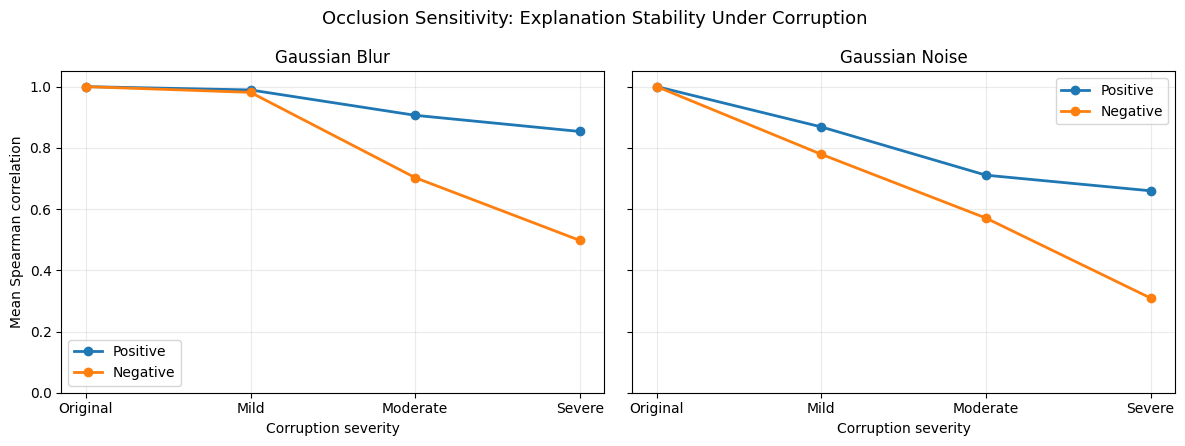

In [ ]:
severity_order = ["Original", "Mild", "Moderate", "Severe"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for ax, corruption in zip(axes, ["Blur", "Noise"]):
    subset = occlusion_stability_summary[
        occlusion_stability_summary["corruption"] == corruption
    ]

    for group in ["Positive", "Negative"]:
        group_data = subset[
            subset["pilot_group"] == group
        ].copy()

        group_data["severity"] = group_data["condition"].apply(
            lambda x: "Original" if x == "Original" else x.split()[0]
        )

        group_data["severity"] = pd.Categorical(
            group_data["severity"],
            categories=severity_order,
            ordered=True
        )

        group_data = group_data.sort_values("severity")

        ax.plot(
            group_data["severity"].astype(str),
            group_data["mean_spearman_similarity"],
            marker="o",
            linewidth=2,
            label=group
        )

    ax.set_title(f"Gaussian {corruption}")
    ax.set_xlabel("Corruption severity")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.25)
    ax.legend()

axes[0].set_ylabel("Mean Spearman correlation")

fig.suptitle(
    "Occlusion Sensitivity: Explanation Stability Under Corruption",
    fontsize=13
)

plt.tight_layout()

fig.savefig(
    OCCLUSION_DIR / "occlusion_spearman_stability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

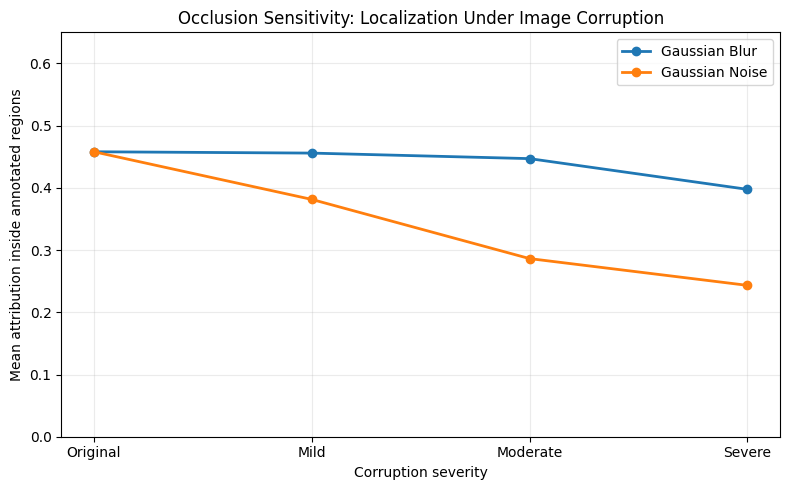

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

for corruption in ["Blur", "Noise"]:
    subset = occlusion_localization_summary[
        occlusion_localization_summary["corruption"] == corruption
    ].copy()

    subset["severity"] = subset["condition"].apply(
        lambda x: "Original" if x == "Original" else x.split()[0]
    )

    subset["severity"] = pd.Categorical(
        subset["severity"],
        categories=severity_order,
        ordered=True
    )

    subset = subset.sort_values("severity")

    ax.plot(
        subset["severity"].astype(str),
        subset["mean_alignment"],
        marker="o",
        linewidth=2,
        label=f"Gaussian {corruption}"
    )

ax.set_title(
    "Occlusion Sensitivity: Localization Under Image Corruption"
)

ax.set_xlabel("Corruption severity")
ax.set_ylabel("Mean attribution inside annotated regions")
ax.set_ylim(0, 0.65)
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()

fig.savefig(
    OCCLUSION_DIR / "occlusion_localization_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### 8.1 Saved Artifacts and Reproducibility

The experiment saves image-level and aggregated results for the Occlusion Sensitivity pilot.

**Saved results:**

- `occlusion_stability_results.csv`: Image-level Spearman stability measurements.
- `occlusion_stability_summary.csv`: Mean stability across corruption conditions and pilot groups.
- `occlusion_localization_alignment.csv`: Localization alignment for annotated positive images.
- `occlusion_localization_summary.csv`: Aggregated localization results.
- Saved attribution maps for original and corrupted images.
- Stability and localization visualizations.

### Required Resources

- RSNA Pneumonia Detection Challenge DICOM archive.
- Radiologist annotation JSON file.
- `Data/model_dataset_split.csv`.
- `Data/pilot_selected_images.csv`.
- `Models/resnet50_best.pth`.
- Shared `xai_utils.py` utilities.

### Dependencies

The notebook uses PyTorch, torchvision, NumPy, pandas, SciPy, pydicom, OpenCV, matplotlib, tqdm, and the Python standard library.

### Execution Order

1. Mount Google Drive and verify project files.
2. Load the saved ResNet-50 model.
3. Extract and preprocess the pilot images.
4. Generate Occlusion Sensitivity maps.
5. Apply Gaussian blur and Gaussian noise.
6. Calculate explanation stability.
7. Calculate localization alignment for annotated positive images.
8. Save results and verify the expected output files.

### Reproducibility Considerations

The model remains fixed throughout the experiment.

The occlusion window size, stride, target-class convention, and preprocessing pipeline are documented to support replication.

Exact reproduction requires access to the source images, selected image identifiers, model checkpoint, and compatible software dependencies.

The notebook is designed for Google Colab and uses project-specific Google Drive paths.


In [ ]:
required_outputs = {
    "Image-level stability": "occlusion_stability_results.csv",
    "Stability summary": "occlusion_stability_summary.csv",
    "Image-level localization": "occlusion_localization_alignment.csv",
    "Localization summary": "occlusion_localization_summary.csv",
    "Stability figure": "occlusion_spearman_stability.png",
    "Localization figure": "occlusion_localization_comparison.png",
}

for description, filename in required_outputs.items():
    path = OCCLUSION_DIR / filename
    print(f"{'✓' if path.exists() else '✗'} {description}: {filename}")

saved_maps = list(MAPS_DIR.glob("*.npz"))

print(f"\nSaved attribution maps: {len(saved_maps)}/84")

ready = (
    all((OCCLUSION_DIR / filename).exists()
        for filename in required_outputs.values())
    and len(saved_maps) == 84
)

print("Ready for XAI comparison:", ready)

✓ Image-level stability: occlusion_stability_results.csv
✓ Stability summary: occlusion_stability_summary.csv
✓ Image-level localization: occlusion_localization_alignment.csv
✓ Localization summary: occlusion_localization_summary.csv
✓ Stability figure: occlusion_spearman_stability.png
✓ Localization figure: occlusion_localization_comparison.png

Saved attribution maps: 84/84
Ready for XAI comparison: True



## 9. Conclusion

This notebook evaluated the stability and localization of Occlusion Sensitivity explanations for a previously trained ResNet50 chest X-ray classifier.

### Key Findings

1. **Explanation stability decreased with increasing corruption severity.** Both Gaussian blur and Gaussian noise altered the ranking of important image regions.

2. **Positive-image explanations were generally more stable than negative-image explanations** under moderate and severe corruption levels in the selected pilot sample.

3. **Localization alignment decreased under image corruption.** The mean alignment for positive images fell from 0.458 on original images to 0.398 under severe blur and 0.243 under severe noise.

4. **Stability and localization capture different properties.** An explanation may remain moderately similar to its original form while becoming less concentrated inside annotated opacity regions.

### Limitations

- **Small sample size:** Only 12 correctly classified test images were evaluated, including six positive cases for localization.
- **Selection bias:** Restricting the pilot to correctly classified images excludes model errors.
- **Occlusion baseline:** Replacing image regions with black squares may create unrealistic inputs.
- **Parameter sensitivity:** The occlusion window size and stride influence the resulting attribution maps.
- **Absolute attribution:** Using absolute values combines positive and negative effects on the target-class score.
- **Bounding-box limitations:** Radiologist annotations identify opacity regions but do not necessarily represent every feature legitimately used by the classifier.
- **Corruption calibration:** The selected blur and noise severities are not directly comparable or clinically calibrated.
- **Limited evaluation scope:** Spearman correlation and localization alignment do not independently establish explanation faithfulness or clinical reliability.


### Connection to the Stability–Localization Disagreement Audit

The pilot demonstrates that explanation stability and localization alignment measure different aspects of attribution behavior.

However, the pilot does not establish how frequently explanations remain highly stable while losing localization alignment.

The larger project evaluates this question using a joint disagreement criterion:

- Spearman explanation stability ≥ 0.80.
- Decrease in localization alignment ≥ 0.05.

These thresholds are exploratory rather than clinically validated.

The final audit compares Occlusion Sensitivity with Score-CAM and Integrated Gradients across 150 annotated positive images and six corruption conditions.

This larger analysis provides the primary evidence for the project's research question, while the present notebook documents the Occlusion Sensitivity implementation and pilot experiments.


### Next Steps

The results from this notebook will be compared with those from **Score-CAM** and **Integrated Gradients**.

The final comparison will examine how the three explanation methods differ in stability and localization under the same image corruptions.

All three methods use the same saved ResNet50 classifier, allowing differences in their explanations to be investigated without retraining the model.
